In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
import pickle
import warnings
warnings.filterwarnings('ignore')
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('D:\PythonProject\Heart_Disease_App\Coranary Artery Disease.csv')

In [3]:
df.head()

,Age,Weight,Length,Sex,BMI,DM,Current Smoker,HTN,EX-Smoker,FH,...,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
0,53.0,90.0,175.0,Male,29.387755,0.0,1.0,1.0,0.0,0.0,...,160,12.00,5.73,23.11,Present,49,25.30,97.20,52,1
1,67.0,70.0,157.0,Fmale,28.398718,0.0,0.0,1.0,0.0,0.0,...,144,0.01,4.41,28.61,Absent,55,28.87,2.06,63,1
2,54.0,54.0,164.0,Male,20.077335,0.0,1.0,0.0,0.0,0.0,...,118,0.08,3.48,32.28,Present,52,29.14,3.81,46,0
3,66.0,67.0,158.0,Fmale,26.838648,0.0,0.0,1.0,0.0,0.0,...,170,7.50,6.41,38.03,Present,51,31.99,24.26,58,1
4,50.0,87.0,153.0,Fmale,37.165193,0.0,0.0,1.0,0.0,0.0,...,134,13.60,3.50,27.78,Present,60,25.99,57.34,49,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 462 entries, 0 to 461
Data columns (total 65 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    303 non-null    float64
 1   Weight                 303 non-null    float64
 2   Length                 303 non-null    float64
 3   Sex                    303 non-null    object 
 4   BMI                    303 non-null    float64
 5   DM                     303 non-null    float64
 6   Current Smoker         303 non-null    float64
 7   HTN                    303 non-null    float64
 8   EX-Smoker              303 non-null    float64
 9   FH                     303 non-null    float64
 10  Obesity                303 non-null    object 
 11  CRF                    303 non-null    object 
 12  CVA                    303 non-null    object 
 13  Airway disease         303 non-null    object 
 14  Thyroid Disease        303 non-null    object 
 15  CHF   

In [5]:
print(df.isnull().sum())

Age        159
Weight     159
Length     159
Sex        159
BMI        159
          ... 
typea        0
obesity      0
alcohol      0
age          0
chd          0
Length: 65, dtype: int64


In [6]:
print(df.columns)

Index(['Age', 'Weight', 'Length', 'Sex', 'BMI', 'DM', 'Current Smoker', 'HTN',
       'EX-Smoker', 'FH', 'Obesity', 'CRF', 'CVA', 'Airway disease',
       'Thyroid Disease', 'CHF', 'DLP', 'BP', 'PR', 'Edema',
       'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur',
       'Diastolic Murmur', 'Typical Chest Pain', 'Dyspnea', 'Function Class',
       'Atypical', 'Nonanginal', 'Exertional CP', 'LowTH Ang', 'Q Wave',
       'St Elevation', 'St Depression', 'Tinversion', 'LVH',
       'Poor R Progression', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR',
       'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA',
       'VHD', 'Cath', 'sbp', 'tobacco', 'ldl', 'adiposity', 'famhist', 'typea',
       'obesity', 'alcohol', 'age', 'chd'],
      dtype='object')


In [7]:
# =====================================================
# CREATE RISK LEVEL FROM CHD
# =====================================================

# Assuming:
# 0 = No Heart Disease
# 1 = Heart Disease

df['risk_level'] = df['chd'].apply(
    lambda x: 'Low' if x == 0 else 'High'
)

# Display sample
print(df[['chd', 'risk_level']].head())

# Distribution
print("\nRisk Distribution:")
print(df['risk_level'].value_counts())

   chd risk_level
0    1       High
1    1       High
2    0        Low
3    1       High
4    1       High

Risk Distribution:
risk_level
Low     302
High    160
Name: count, dtype: int64


In [9]:
numerical_cols = [
    'age',
    'BMI',
    'tobacco',
    'LDL',
    'HDL',
    'BP'
]

categorical_cols = [
    'gender',
    'smoking',
    'hypertension',
    'diabetes',
    'family_history',
    'obesity',
    'alcohol',
    'chest_pain',
    'breathlessness',
    'exercise_pain'
]

In [10]:
df.rename(columns={

    'Sex': 'gender',

    'Current Smoker': 'smoking',

    'HTN': 'hypertension',

    'DM': 'diabetes',

    'famhist': 'family_history',

    'Typical Chest Pain': 'chest_pain',

    'Dyspnea': 'breathlessness',

    'Exertional CP': 'exercise_pain'

}, inplace=True)

print(df.columns)

Index(['Age', 'Weight', 'Length', 'gender', 'BMI', 'diabetes', 'smoking',
       'hypertension', 'EX-Smoker', 'FH', 'Obesity', 'CRF', 'CVA',
       'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'BP', 'PR', 'Edema',
       'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur',
       'Diastolic Murmur', 'chest_pain', 'breathlessness', 'Function Class',
       'Atypical', 'Nonanginal', 'exercise_pain', 'LowTH Ang', 'Q Wave',
       'St Elevation', 'St Depression', 'Tinversion', 'LVH',
       'Poor R Progression', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR',
       'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA',
       'VHD', 'Cath', 'sbp', 'tobacco', 'ldl', 'adiposity', 'family_history',
       'typea', 'obesity', 'alcohol', 'age', 'chd', 'risk_level'],
      dtype='object')


In [11]:
from sklearn.impute import SimpleImputer

# Numerical Imputer
num_imputer = SimpleImputer(strategy='median')

df[numerical_cols] = num_imputer.fit_transform(
    df[numerical_cols]
)

# Categorical Imputer
cat_imputer = SimpleImputer(strategy='most_frequent')

df[categorical_cols] = cat_imputer.fit_transform(
    df[categorical_cols]
)

print(df.isnull().sum())

Age           159
Weight        159
Length        159
gender          0
BMI             0
             ... 
obesity         0
alcohol         0
age             0
chd             0
risk_level      0
Length: 66, dtype: int64


In [12]:
from sklearn.preprocessing import LabelEncoder

# Categorical columns
categorical_cols = [
    'gender',
    'smoking',
    'hypertension',
    'diabetes',
    'family_history',
    'obesity',
    'alcohol',
    'chest_pain',
    'breathlessness',
    'exercise_pain'
]

encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    df[col] = le.fit_transform(
        df[col].astype(str)
    )

    encoders[col] = le

print(df.head())

    Age  Weight  Length  gender        BMI  diabetes  smoking  hypertension  \
0  53.0    90.0   175.0       1  29.387755         0        1             1   
1  67.0    70.0   157.0       0  28.398718         0        0             1   
2  54.0    54.0   164.0       1  20.077335         0        1             0   
3  66.0    67.0   158.0       0  26.838648         0        0             1   
4  50.0    87.0   153.0       0  37.165193         0        0             1   

   EX-Smoker   FH  ... tobacco   ldl adiposity family_history typea obesity  \
0        0.0  0.0  ...   12.00  5.73     23.11              1    49     176   
1        0.0  0.0  ...    0.01  4.41     28.61              0    55     305   
2        0.0  0.0  ...    0.08  3.48     32.28              1    52     312   
3        0.0  0.0  ...    7.50  6.41     38.03              1    51     366   
4        0.0  0.0  ...   13.60  3.50     27.78              1    60     201   

  alcohol   age  chd  risk_level  
0     248  52.0

In [13]:
# =========================================================
# SELECT ONLY USER-FRIENDLY FEATURES
# REMOVE DATA LEAKAGE FEATURES
# =========================================================

selected_features = [

    'age',

    'gender',

    'BMI',

    'smoking',

    'hypertension',

    'diabetes',

    'family_history',

    'obesity',

    'alcohol',

    'tobacco',

    'LDL',

    'HDL',

    'BP',

    'chest_pain',

    'breathlessness',

    'exercise_pain',

    'risk_level'
]

df = df[selected_features]

print(df.head())
print(df.shape)

    age  gender        BMI  smoking  hypertension  diabetes  family_history  \
0  52.0       1  29.387755        1             1         0               1   
1  63.0       0  28.398718        0             1         0               0   
2  46.0       1  20.077335        1             0         0               1   
3  58.0       0  26.838648        0             1         0               1   
4  49.0       0  37.165193        0             1         0               1   

   obesity  alcohol  tobacco    LDL   HDL     BP  chest_pain  breathlessness  \
0      176      248    12.00  155.0  30.0  110.0           0               0   
1      305       77     0.01  121.0  36.0  140.0           1               0   
2      312      136     0.08   70.0  45.0  100.0           1               0   
3      366      103     7.50   55.0  27.0  100.0           0               1   
4      201      195    13.60  110.0  50.0  110.0           0               1   

   exercise_pain risk_level  
0             

In [14]:
from sklearn.preprocessing import LabelEncoder

# Automatically detect categorical columns
categorical_cols = df.select_dtypes(
    include=['object']
).columns

print("Categorical Columns:")
print(categorical_cols)

# Encode
encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    df[col] = le.fit_transform(
        df[col].astype(str)
    )

    encoders[col] = le

print("\nEncoding Completed")
print(df.head())

Categorical Columns:
Index(['risk_level'], dtype='object')

Encoding Completed
    age  gender        BMI  smoking  hypertension  diabetes  family_history  \
0  52.0       1  29.387755        1             1         0               1   
1  63.0       0  28.398718        0             1         0               0   
2  46.0       1  20.077335        1             0         0               1   
3  58.0       0  26.838648        0             1         0               1   
4  49.0       0  37.165193        0             1         0               1   

   obesity  alcohol  tobacco    LDL   HDL     BP  chest_pain  breathlessness  \
0      176      248    12.00  155.0  30.0  110.0           0               0   
1      305       77     0.01  121.0  36.0  140.0           1               0   
2      312      136     0.08   70.0  45.0  100.0           1               0   
3      366      103     7.50   55.0  27.0  100.0           0               1   
4      201      195    13.60  110.0  50.0  110

In [43]:
print(df.columns.tolist())

['age', 'gender', 'BMI', 'smoking', 'hypertension', 'diabetes', 'family_history', 'obesity', 'alcohol', 'tobacco', 'LDL', 'HDL', 'BP', 'chest_pain', 'breathlessness', 'exercise_pain', 'risk_level']


In [44]:
X = df.drop('risk_level', axis=1)

numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 0.62933573  0.61571461  0.69309173  2.51661148  0.60569291 -0.49186938
   1.18585412 -0.17783109  1.96507767  1.82307289  1.81005538 -1.14632633
  -1.28699681 -1.52438217 -0.63916867  0.        ]
 [ 1.3831147  -1.62412908  0.39532854 -0.39735971  0.60569291 -0.49186938
  -0.84327404  0.96583755 -0.15205448 -0.79023744  0.6255222  -0.4451598
   0.67212189  0.65600347 -0.63916867  0.        ]
 [ 0.21818356  0.61571461 -2.10993798  2.51661148 -1.65100165 -0.49186938
   1.18585412  1.02789709  0.57841802 -0.77498042 -1.15127757  0.60658999
  -1.94003638  0.65600347 -0.63916867  0.        ]
 [ 1.04048789 -1.62412908 -0.07435204 -0.39735971  0.60569291 -0.49186938
   1.18585412  1.50664211  0.16984866  0.84226418 -1.67386574 -1.49690959
  -1.94003638 -1.52438217  1.56453226  0.        ]
 [ 0.42375964 -1.62412908  3.03459605 -0.39735971  0.60569291 -0.49186938
   1.18585412  0.04381012  1.30889051  2.17180488  0.24229088  1.19089543
  -1.28699681 -1.52438217  1.56453226  0.        ]]


In [46]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("oktayrdeki/heart-disease")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\visha\.cache\kagglehub\datasets\oktayrdeki\heart-disease\versions\1


In [47]:
import os

In [48]:
# =========================================================
# CHECK FILES INSIDE DATASET FOLDER
# =========================================================

print(os.listdir(path))

['heart_disease.csv']


In [49]:
# =========================================================
# LOAD KAGGLE DATASET CORRECTLY
# =========================================================

import pandas as pd
import os

# Check files
print(os.listdir(path))

# Load correct file
df2 = pd.read_csv(
    os.path.join(path, "heart_disease.csv")
)

# View dataset
print(df2.head())

print(df2.shape)

['heart_disease.csv']
    Age  Gender  Blood Pressure  Cholesterol Level Exercise Habits Smoking  \
0  56.0    Male           153.0              155.0            High     Yes   
1  69.0  Female           146.0              286.0            High      No   
2  46.0    Male           126.0              216.0             Low      No   
3  32.0  Female           122.0              293.0            High     Yes   
4  60.0    Male           166.0              242.0             Low     Yes   

  Family Heart Disease Diabetes        BMI High Blood Pressure  ...  \
0                  Yes       No  24.991591                 Yes  ...   
1                  Yes      Yes  25.221799                  No  ...   
2                   No       No  29.855447                  No  ...   
3                  Yes       No  24.130477                 Yes  ...   
4                  Yes      Yes  20.486289                 Yes  ...   

  High LDL Cholesterol Alcohol Consumption Stress Level Sleep Hours  \
0          

In [50]:
# =========================================================
# RENAME COLUMNS FOR CONSISTENCY
# =========================================================

df2.rename(columns={

    'Sex': 'gender',

    'Age': 'age',

    'Smoking': 'smoking',

    'FamilyHistory': 'family_history',

    'AlcoholConsumption': 'alcohol',

    'BMI': 'BMI',

    'Diabetes': 'diabetes',

    'BloodPressure': 'BP',

    'Cholesterol': 'LDL',

    'ChestPain': 'chest_pain',

    'ShortnessOfBreath': 'breathlessness',

    'HeartDisease': 'risk_level'

}, inplace=True)

print(df2.columns)

Index(['age', 'Gender', 'Blood Pressure', 'Cholesterol Level',
       'Exercise Habits', 'smoking', 'Family Heart Disease', 'diabetes', 'BMI',
       'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol',
       'Alcohol Consumption', 'Stress Level', 'Sleep Hours',
       'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar',
       'CRP Level', 'Homocysteine Level', 'Heart Disease Status'],
      dtype='object')


In [51]:
common_features = [

    'age',

    'gender',

    'BMI',

    'smoking',

    'hypertension',

    'diabetes',

    'family_history',

    'obesity',

    'alcohol',

    'tobacco',

    'LDL',

    'HDL',

    'BP',

    'chest_pain',

    'breathlessness',

    'exercise_pain',

    'risk_level'
]

In [52]:
# Add missing columns in df2
for col in common_features:

    if col not in df2.columns:

        df2[col] = 0

# Add missing columns in df
for col in common_features:

    if col not in df.columns:

        df[col] = 0

In [53]:
df = df[common_features]

df2 = df2[common_features]

In [54]:
merged_df = pd.concat(

    [df, df2],

    ignore_index=True
)

print(merged_df.shape)

print(merged_df.head())

(10462, 17)
    age  gender        BMI smoking  hypertension diabetes  family_history  \
0  52.0       1  29.387755       1             1        0               1   
1  63.0       0  28.398718       0             1        0               0   
2  46.0       1  20.077335       1             0        0               1   
3  58.0       0  26.838648       0             1        0               1   
4  49.0       0  37.165193       0             1        0               1   

   obesity  alcohol  tobacco    LDL   HDL     BP  chest_pain  breathlessness  \
0      176      248    12.00  155.0  30.0  110.0           0               0   
1      305       77     0.01  121.0  36.0  140.0           1               0   
2      312      136     0.08   70.0  45.0  100.0           1               0   
3      366      103     7.50   55.0  27.0  100.0           0               1   
4      201      195    13.60  110.0  50.0  110.0           0               1   

   exercise_pain  risk_level  
0            

In [55]:
print(merged_df.isnull().sum())

age               29
gender             0
BMI               22
smoking           25
hypertension       0
diabetes          30
family_history     0
obesity            0
alcohol            0
tobacco            0
LDL                0
HDL                0
BP                 0
chest_pain         0
breathlessness     0
exercise_pain      0
risk_level         0
dtype: int64


In [56]:
from sklearn.impute import SimpleImputer

# Numerical columns
numerical_cols = merged_df.select_dtypes(
    include=['int64', 'float64']
).columns

# Remove target
numerical_cols = numerical_cols.drop('risk_level')

# Categorical columns
categorical_cols = merged_df.select_dtypes(
    include=['object']
).columns

# Numerical imputation
num_imputer = SimpleImputer(strategy='median')

merged_df[numerical_cols] = num_imputer.fit_transform(
    merged_df[numerical_cols]
)

# Categorical imputation
cat_imputer = SimpleImputer(strategy='most_frequent')

merged_df[categorical_cols] = cat_imputer.fit_transform(
    merged_df[categorical_cols]
)

print(merged_df.isnull().sum())

age               0
gender            0
BMI               0
smoking           0
hypertension      0
diabetes          0
family_history    0
obesity           0
alcohol           0
tobacco           0
LDL               0
HDL               0
BP                0
chest_pain        0
breathlessness    0
exercise_pain     0
risk_level        0
dtype: int64


In [57]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = merged_df.select_dtypes(
    include=['object']
).columns

encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    merged_df[col] = le.fit_transform(
        merged_df[col].astype(str)
    )

    encoders[col] = le

print(merged_df.head())

    age  gender        BMI  smoking  hypertension  diabetes  family_history  \
0  52.0     1.0  29.387755        1           1.0         0             1.0   
1  63.0     0.0  28.398718        0           1.0         0             0.0   
2  46.0     1.0  20.077335        1           0.0         0             1.0   
3  58.0     0.0  26.838648        0           1.0         0             1.0   
4  49.0     0.0  37.165193        0           1.0         0             1.0   

   obesity  alcohol  tobacco    LDL   HDL     BP  chest_pain  breathlessness  \
0    176.0    248.0    12.00  155.0  30.0  110.0         0.0             0.0   
1    305.0     77.0     0.01  121.0  36.0  140.0         1.0             0.0   
2    312.0    136.0     0.08   70.0  45.0  100.0         1.0             0.0   
3    366.0    103.0     7.50   55.0  27.0  100.0         0.0             1.0   
4    201.0    195.0    13.60  110.0  50.0  110.0         0.0             1.0   

   exercise_pain  risk_level  
0            

In [58]:
X = merged_df.drop('risk_level', axis=1)

y = merged_df['risk_level']

print(X.shape)
print(y.shape)

(10462, 16)
(10462,)


In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 1.65481278e-01  5.49816794e+00  6.42314041e-02 -2.02906378e+00
   5.47290259e+00 -3.49430655e+00  7.31365732e+00  3.58052164e+00
   9.76582866e+00  9.70740541e+00  6.83451659e+00  3.37251535e+00
   3.88465466e+00 -1.78485812e-01 -1.13905392e-01  0.00000000e+00]
 [ 7.74127014e-01 -1.81878766e-01 -9.49802258e-02 -3.46835223e+00
   5.47290259e+00 -3.49430655e+00 -1.36730497e-01  6.34065974e+00
   2.92335209e+00 -1.23438676e-01  5.28998826e+00  4.08900398e+00
   5.00230367e+00  5.60268622e+00 -1.13905392e-01  0.00000000e+00]
 [-1.66507305e-01  5.49816794e+00 -1.43452650e+00 -2.02906378e+00
  -1.82718399e-01 -3.49430655e+00  7.31365732e+00  6.49043468e+00
   5.28420658e+00 -6.60442568e-02  2.97319576e+00  5.16373692e+00
   3.51210499e+00  5.60268622e+00 -1.13905392e-01  0.00000000e+00]
 [ 4.97469861e-01 -1.81878766e-01 -3.46114732e-01 -3.46835223e+00
   5.47290259e+00 -3.49430655e+00  7.31365732e+00  7.64584132e+00
   3.96372865e+00  6.01776418e+00  2.29178620e+00  3.01427104e+00
   3.51

In [60]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(
    X_scaled,
    y
)

print(pd.Series(y_resampled).value_counts())

risk_level
0    10160
1    10160
Name: count, dtype: int64


In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X_resampled,

    y_resampled,

    test_size=0.2,

    random_state=42,

    stratify=y_resampled
)

print(X_train.shape)
print(X_test.shape)

(16256, 16)
(4064, 16)


In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

rf = RandomForestClassifier(

    n_estimators=500,

    max_depth=12,

    min_samples_split=4,

    min_samples_leaf=2,

    max_features='sqrt',

    bootstrap=True,

    class_weight='balanced',

    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("================================")
print("RANDOM FOREST RESULTS")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

RANDOM FOREST RESULTS

Accuracy:
0.9918799212598425

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      2032
           1       0.98      1.00      0.99      2032

    accuracy                           0.99      4064
   macro avg       0.99      0.99      0.99      4064
weighted avg       0.99      0.99      0.99      4064



In [63]:
from xgboost import XGBClassifier

xgb = XGBClassifier(

    n_estimators=500,

    learning_rate=0.03,

    max_depth=4,

    subsample=0.8,

    colsample_bytree=0.8,

    gamma=1,

    reg_alpha=0.5,

    reg_lambda=1,

    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

print("================================")
print("XGBOOST RESULTS")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, xgb_pred))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

XGBOOST RESULTS

Accuracy:
0.9923720472440944

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      2032
           1       0.98      1.00      0.99      2032

    accuracy                           0.99      4064
   macro avg       0.99      0.99      0.99      4064
weighted avg       0.99      0.99      0.99      4064



In [64]:
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier

nb = GaussianNB()

ensemble_model = VotingClassifier(

    estimators=[

        ('rf', rf),

        ('xgb', xgb),

        ('nb', nb)

    ],

    voting='soft'
)

ensemble_model.fit(X_train, y_train)

ensemble_pred = ensemble_model.predict(X_test)

print("================================")
print("FINAL ENSEMBLE RESULTS")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, ensemble_pred))

print("\nClassification Report:")
print(classification_report(y_test, ensemble_pred))

FINAL ENSEMBLE RESULTS

Accuracy:
0.9918799212598425

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      2032
           1       0.98      1.00      0.99      2032

    accuracy                           0.99      4064
   macro avg       0.99      0.99      0.99      4064
weighted avg       0.99      0.99      0.99      4064



           Feature  Importance
10             LDL    0.217164
7          obesity    0.201631
12              BP    0.138449
11             HDL    0.119620
5         diabetes    0.118843
3          smoking    0.111639
8          alcohol    0.042362
9          tobacco    0.022426
1           gender    0.011725
4     hypertension    0.006793
13      chest_pain    0.004196
0              age    0.002778
2              BMI    0.001326
14  breathlessness    0.000563
6   family_history    0.000484
15   exercise_pain    0.000000


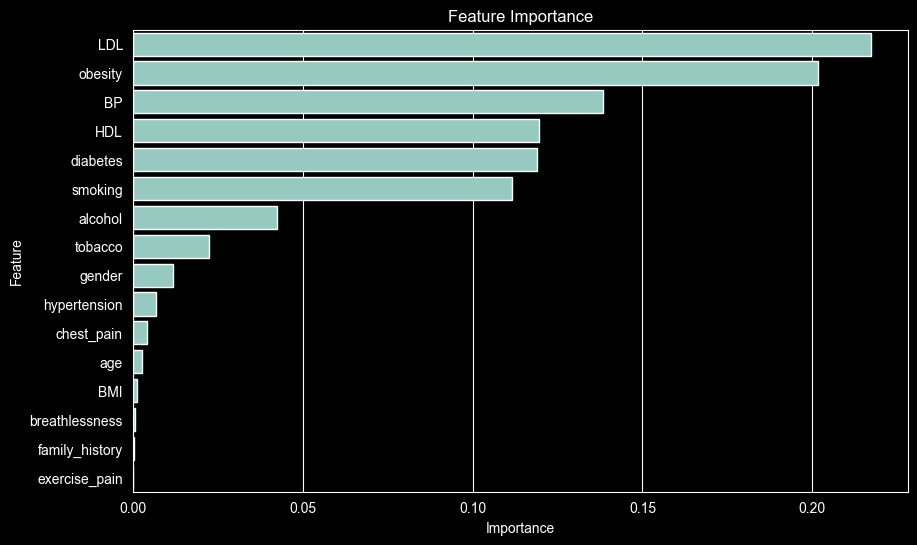

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance_df = pd.DataFrame({

    'Feature': X.columns,

    'Importance': rf.feature_importances_

})

importance_df = importance_df.sort_values(

    by='Importance',

    ascending=False
)

print(importance_df)

# Plot
plt.figure(figsize=(10,6))

sns.barplot(

    x='Importance',

    y='Feature',

    data=importance_df
)

plt.title("Feature Importance")

plt.show()

In [66]:
# =========================================================
# FINAL CLINICALLY MEANINGFUL FEATURES
# =========================================================

selected_features = [

    'age',

    'gender',

    'BMI',

    'smoking',

    'hypertension',

    'diabetes',

    'family_history',

    'obesity',

    'alcohol',

    'tobacco',

    'LDL',

    'HDL',

    'BP',

    'chest_pain',

    'breathlessness',

    'exercise_pain',

    'risk_level'
]

df = df[selected_features]

print(df.head())

print(df.shape)

    age  gender        BMI  smoking  hypertension  diabetes  family_history  \
0  52.0       1  29.387755        1             1         0               1   
1  63.0       0  28.398718        0             1         0               0   
2  46.0       1  20.077335        1             0         0               1   
3  58.0       0  26.838648        0             1         0               1   
4  49.0       0  37.165193        0             1         0               1   

   obesity  alcohol  tobacco    LDL   HDL     BP  chest_pain  breathlessness  \
0      176      248    12.00  155.0  30.0  110.0           0               0   
1      305       77     0.01  121.0  36.0  140.0           1               0   
2      312      136     0.08   70.0  45.0  100.0           1               0   
3      366      103     7.50   55.0  27.0  100.0           0               1   
4      201      195    13.60  110.0  50.0  110.0           0               1   

   exercise_pain  risk_level  
0            

In [67]:
print(df.isnull().sum())

age               0
gender            0
BMI               0
smoking           0
hypertension      0
diabetes          0
family_history    0
obesity           0
alcohol           0
tobacco           0
LDL               0
HDL               0
BP                0
chest_pain        0
breathlessness    0
exercise_pain     0
risk_level        0
dtype: int64


In [70]:
numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_cols = X.select_dtypes(
    include=['object']
).columns

In [71]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = df.select_dtypes(
    include=['object']
).columns

encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    df[col] = le.fit_transform(
        df[col].astype(str)
    )

    encoders[col] = le

print(df.head())

    age  gender        BMI  smoking  hypertension  diabetes  family_history  \
0  52.0       1  29.387755        1             1         0               1   
1  63.0       0  28.398718        0             1         0               0   
2  46.0       1  20.077335        1             0         0               1   
3  58.0       0  26.838648        0             1         0               1   
4  49.0       0  37.165193        0             1         0               1   

   obesity  alcohol  tobacco    LDL   HDL     BP  chest_pain  breathlessness  \
0      176      248    12.00  155.0  30.0  110.0           0               0   
1      305       77     0.01  121.0  36.0  140.0           1               0   
2      312      136     0.08   70.0  45.0  100.0           1               0   
3      366      103     7.50   55.0  27.0  100.0           0               1   
4      201      195    13.60  110.0  50.0  110.0           0               1   

   exercise_pain  risk_level  
0            

In [72]:
X = df.drop('risk_level', axis=1)

y = df['risk_level']

print(X.shape)
print(y.shape)

(462, 16)
(462,)


In [73]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 0.62933573  0.61571461  0.69309173  2.51661148  0.60569291 -0.49186938
   1.18585412 -0.17783109  1.96507767  1.82307289  1.81005538 -1.14632633
  -1.28699681 -1.52438217 -0.63916867  0.        ]
 [ 1.3831147  -1.62412908  0.39532854 -0.39735971  0.60569291 -0.49186938
  -0.84327404  0.96583755 -0.15205448 -0.79023744  0.6255222  -0.4451598
   0.67212189  0.65600347 -0.63916867  0.        ]
 [ 0.21818356  0.61571461 -2.10993798  2.51661148 -1.65100165 -0.49186938
   1.18585412  1.02789709  0.57841802 -0.77498042 -1.15127757  0.60658999
  -1.94003638  0.65600347 -0.63916867  0.        ]
 [ 1.04048789 -1.62412908 -0.07435204 -0.39735971  0.60569291 -0.49186938
   1.18585412  1.50664211  0.16984866  0.84226418 -1.67386574 -1.49690959
  -1.94003638 -1.52438217  1.56453226  0.        ]
 [ 0.42375964 -1.62412908  3.03459605 -0.39735971  0.60569291 -0.49186938
   1.18585412  0.04381012  1.30889051  2.17180488  0.24229088  1.19089543
  -1.28699681 -1.52438217  1.56453226  0.        ]]


In [74]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(
    X_scaled,
    y
)

print(pd.Series(y_resampled).value_counts())

risk_level
0    302
1    302
Name: count, dtype: int64


In [75]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X_resampled,

    y_resampled,

    test_size=0.2,

    random_state=42,

    stratify=y_resampled
)

print(X_train.shape)
print(X_test.shape)

(483, 16)
(121, 16)


In [76]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

rf = RandomForestClassifier(

    n_estimators=500,

    max_depth=10,

    min_samples_split=4,

    min_samples_leaf=2,

    max_features='sqrt',

    class_weight='balanced',

    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("================================")
print("RANDOM FOREST RESULTS")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

RANDOM FOREST RESULTS

Accuracy:
0.7603305785123967

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.77      0.76        61
           1       0.76      0.75      0.76        60

    accuracy                           0.76       121
   macro avg       0.76      0.76      0.76       121
weighted avg       0.76      0.76      0.76       121



In [77]:
from xgboost import XGBClassifier

xgb = XGBClassifier(

    n_estimators=500,

    learning_rate=0.03,

    max_depth=4,

    subsample=0.8,

    colsample_bytree=0.8,

    gamma=1,

    reg_alpha=0.5,

    reg_lambda=1,

    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

print("================================")
print("XGBOOST RESULTS")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, xgb_pred))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

XGBOOST RESULTS

Accuracy:
0.6942148760330579

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.72      0.70        61
           1       0.70      0.67      0.68        60

    accuracy                           0.69       121
   macro avg       0.69      0.69      0.69       121
weighted avg       0.69      0.69      0.69       121



In [78]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)

print("================================")
print("NAIVE BAYES RESULTS")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, nb_pred))

print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

NAIVE BAYES RESULTS

Accuracy:
0.7520661157024794

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.77      0.76        61
           1       0.76      0.73      0.75        60

    accuracy                           0.75       121
   macro avg       0.75      0.75      0.75       121
weighted avg       0.75      0.75      0.75       121



In [79]:
from sklearn.ensemble import VotingClassifier

ensemble_model = VotingClassifier(

    estimators=[

        ('rf', rf),

        ('xgb', xgb),

        ('nb', nb)

    ],

    voting='soft'
)

ensemble_model.fit(X_train, y_train)

ensemble_pred = ensemble_model.predict(X_test)

print("================================")
print("FINAL ENSEMBLE RESULTS")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, ensemble_pred))

print("\nClassification Report:")
print(classification_report(y_test, ensemble_pred))

FINAL ENSEMBLE RESULTS

Accuracy:
0.71900826446281

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.70      0.72        61
           1       0.71      0.73      0.72        60

    accuracy                           0.72       121
   macro avg       0.72      0.72      0.72       121
weighted avg       0.72      0.72      0.72       121



           Feature  Importance
0              age    0.217528
9          tobacco    0.170664
7          obesity    0.094020
2              BMI    0.090392
6   family_history    0.087508
8          alcohol    0.082689
10             LDL    0.075560
11             HDL    0.060279
12              BP    0.040817
14  breathlessness    0.017589
4     hypertension    0.016392
13      chest_pain    0.014167
1           gender    0.013003
5         diabetes    0.010416
3          smoking    0.008974
15   exercise_pain    0.000000


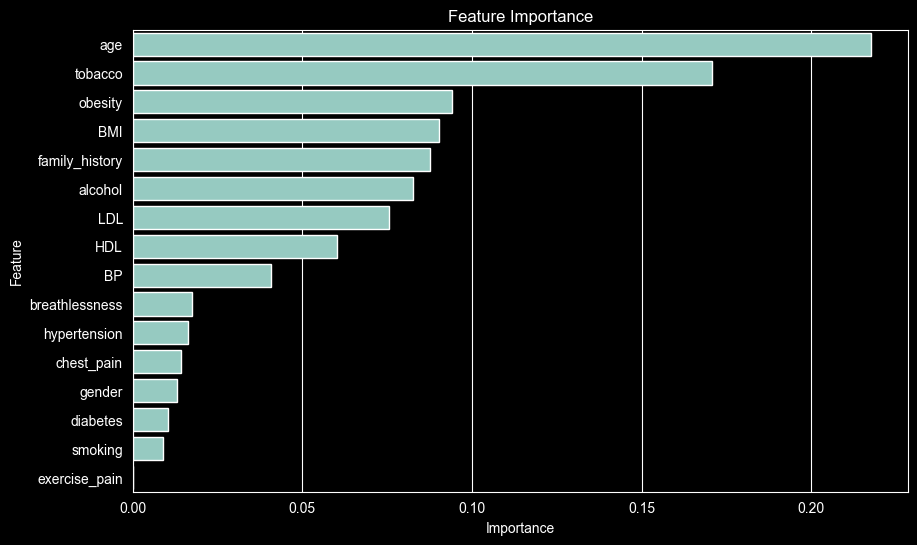

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

importance_df = pd.DataFrame({

    'Feature': X.columns,

    'Importance': rf.feature_importances_

})

importance_df = importance_df.sort_values(

    by='Importance',

    ascending=False
)

print(importance_df)

# Plot
plt.figure(figsize=(10,6))

sns.barplot(

    x='Importance',

    y='Feature',

    data=importance_df
)

plt.title("Feature Importance")

plt.show()

In [81]:
!pip install shap


[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


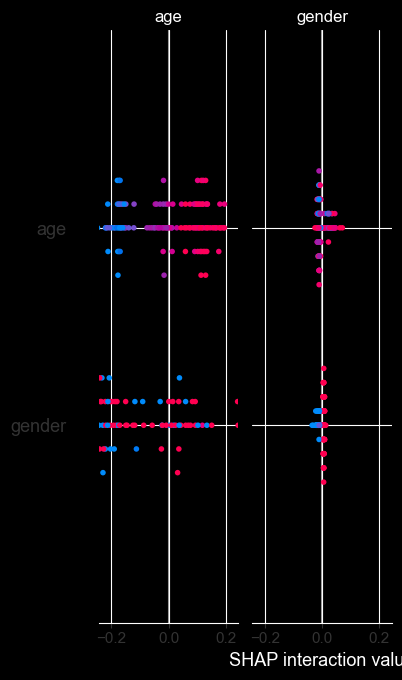

In [82]:
import shap

explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(

    shap_values,

    X_test,

    feature_names=X.columns
)

In [83]:
rf.fit(X_train, y_train)

rf_probs = rf.predict_proba(X_test)[:,1]

In [84]:
xgb.fit(X_train, y_train)

xgb_probs = xgb.predict_proba(X_test)[:,1]

In [85]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

ann = Sequential()

# Input Layer
ann.add(Dense(
    128,
    activation='relu',
    input_shape=(X_train.shape[1],)
))

ann.add(Dropout(0.3))

# Hidden Layer
ann.add(Dense(
    64,
    activation='relu'
))

ann.add(Dropout(0.2))

# Hidden Layer
ann.add(Dense(
    32,
    activation='relu'
))

# Output Layer
ann.add(Dense(
    1,
    activation='sigmoid'
))

ann.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=['accuracy']
)

early_stop = EarlyStopping(

    monitor='val_loss',

    patience=10,

    restore_best_weights=True
)

history = ann.fit(

    X_train,

    y_train,

    epochs=100,

    batch_size=16,

    validation_split=0.2,

    callbacks=[early_stop]
)



Epoch 1/100


25/25 [==============================] - 2s 15ms/step - loss: 0.7097 - accuracy: 0.5181 - val_loss: 0.6473 - val_accuracy: 0.7113
Epoch 2/100
25/25 [==============================] - 0s 6ms/step - loss: 0.6440 - accuracy: 0.6658 - val_loss: 0.6059 - val_accuracy: 0.7423
Epoch 3/100
25/25 [==============================] - 0s 5ms/step - loss: 0.6057 - accuracy: 0.6762 - val_loss: 0.5835 - val_accuracy: 0.6907
Epoch 4/100
25/25 [==============================] - 0s 5ms/step - loss: 0.5760 - accuracy: 0.6969 - val_loss: 0.5437 - val_accuracy: 0.7423
Epoch 5/100
25/25 [==============================] - 0s 5ms/step - loss: 0.5534 - accuracy: 0.7254 - val_loss: 0.5358 - val_accuracy: 0.7526
Epoch 6/100
25/25 [==============================] - 0s 4ms/step - loss: 0.5515 - accuracy: 0.7280 - val_loss: 0.5413 - val_accuracy: 0.7320
Epoch 7/100
25/25 [==============================] - 0s 5ms/step - loss: 0.5268 - accuracy: 0.7435 - val_loss: 0.5339 - val_accuracy: 0.7732
Epoch 8/

In [86]:
ann_probs = ann.predict(X_test).flatten()

4/4 [==============================] - 0s 2ms/step


In [87]:
import numpy as np

# Weighted averaging

hybrid_probs = (

    0.4 * rf_probs +

    0.4 * xgb_probs +

    0.2 * ann_probs
)

In [88]:
hybrid_pred = (hybrid_probs > 0.5).astype(int)

In [89]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("================================")
print("HYBRID ML + DL MODEL")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, hybrid_pred))

print("\nClassification Report:")
print(classification_report(y_test, hybrid_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, hybrid_pred))

HYBRID ML + DL MODEL

Accuracy:
0.7355371900826446

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.74      0.74        61
           1       0.73      0.73      0.73        60

    accuracy                           0.74       121
   macro avg       0.74      0.74      0.74       121
weighted avg       0.74      0.74      0.74       121


Confusion Matrix:
[[45 16]
 [16 44]]


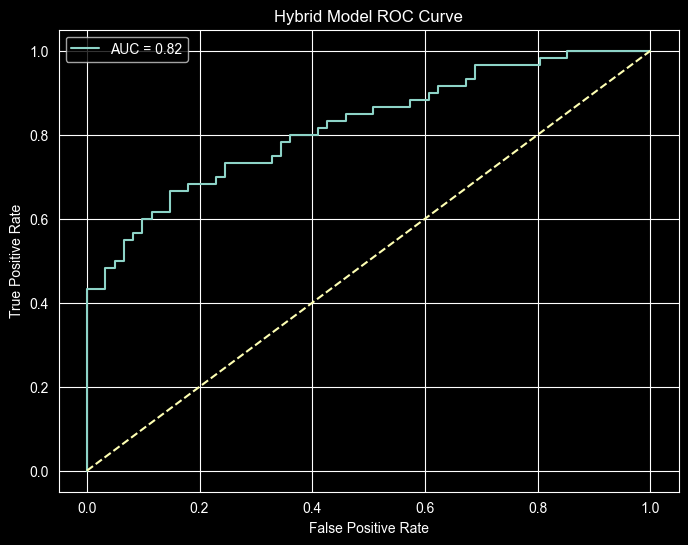

In [90]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    hybrid_probs
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Hybrid Model ROC Curve")

plt.legend()

plt.show()

In [91]:
def risk_level(prob):

    if prob < 0.3:
        return "Low"

    elif prob < 0.6:
        return "Moderate"

    else:
        return "High"

# Example
risk_categories = [

    risk_level(p)

    for p in hybrid_probs
]

print(risk_categories[:10])

['Moderate', 'Low', 'Low', 'High', 'Low', 'Low', 'High', 'Low', 'High', 'Moderate']


In [92]:
rf.fit(X_train, y_train)

xgb.fit(X_train, y_train)

ann.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    verbose=0
)

In [93]:
rf_train_probs = rf.predict_proba(X_train)[:,1]

xgb_train_probs = xgb.predict_proba(X_train)[:,1]

ann_train_probs = ann.predict(X_train).flatten()

16/16 [==============================] - 0s 2ms/step


In [94]:
import numpy as np

meta_X_train = np.column_stack([

    rf_train_probs,

    xgb_train_probs,

    ann_train_probs
])

print(meta_X_train.shape)

(483, 3)


In [95]:
rf_test_probs = rf.predict_proba(X_test)[:,1]

xgb_test_probs = xgb.predict_proba(X_test)[:,1]

ann_test_probs = ann.predict(X_test).flatten()

meta_X_test = np.column_stack([

    rf_test_probs,

    xgb_test_probs,

    ann_test_probs
])

4/4 [==============================] - 0s 2ms/step


In [101]:
from sklearn.linear_model import LogisticRegression

meta_model = LogisticRegression()

meta_model.fit(
    meta_X_train,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [97]:
stack_pred = meta_model.predict(meta_X_test)

In [98]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print("================================")
print("STACKED HYBRID MODEL")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, stack_pred))

print("\nClassification Report:")
print(classification_report(y_test, stack_pred))

STACKED HYBRID MODEL

Accuracy:
0.7768595041322314

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.79      0.78        61
           1       0.78      0.77      0.77        60

    accuracy                           0.78       121
   macro avg       0.78      0.78      0.78       121
weighted avg       0.78      0.78      0.78       121



In [99]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print("================================")
print("STACKED HYBRID MODEL")
print("================================")

print("\nAccuracy:")
print(accuracy_score(y_test, stack_pred))

print("\nClassification Report:")
print(classification_report(y_test, stack_pred))

STACKED HYBRID MODEL

Accuracy:
0.7768595041322314

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.79      0.78        61
           1       0.78      0.77      0.77        60

    accuracy                           0.78       121
   macro avg       0.78      0.78      0.78       121
weighted avg       0.78      0.78      0.78       121



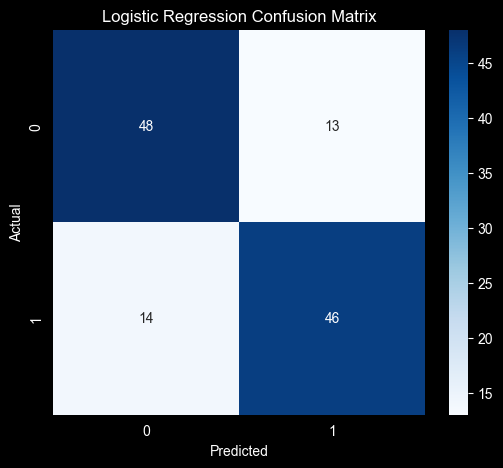

In [106]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create model
meta_model = LogisticRegression()

# Train model
meta_model.fit(
    meta_X_train,
    y_train
)

# Predict
lr_pred = meta_model.predict(meta_X_test)

# Confusion matrix
cm = confusion_matrix(y_test, lr_pred)

# Plot
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

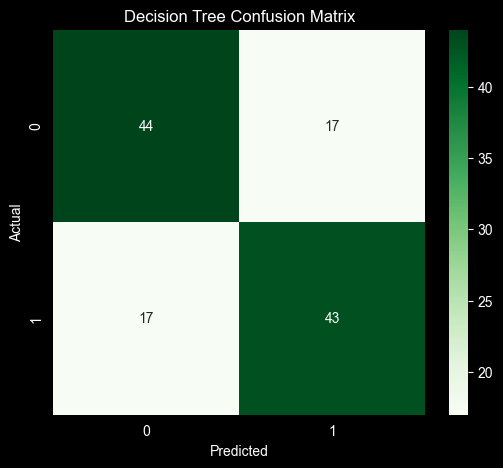

In [107]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create model
dt_model = DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(X_train, y_train)

# Predict
dt_pred = dt_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, dt_pred)

# Plot
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Decision Tree Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

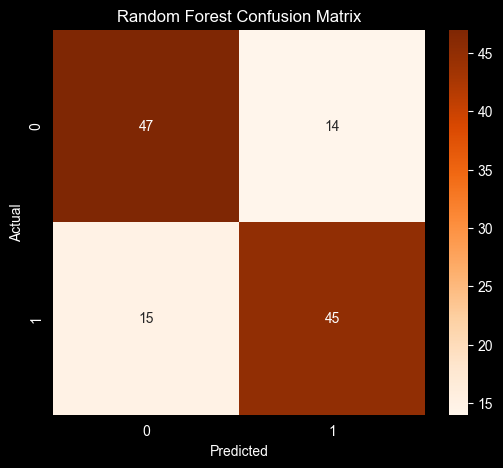

In [108]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='Oranges'
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

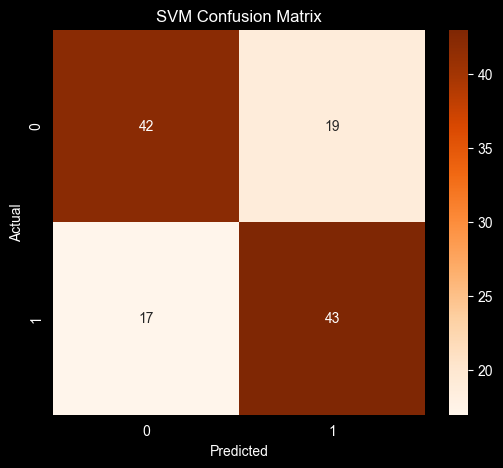

In [110]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create SVM model
svm_model = SVC(kernel='rbf', random_state=42)

# Train model
svm_model.fit(X_train, y_train)

# Predict
svm_pred = svm_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, svm_pred)

# Plot
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title("SVM Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

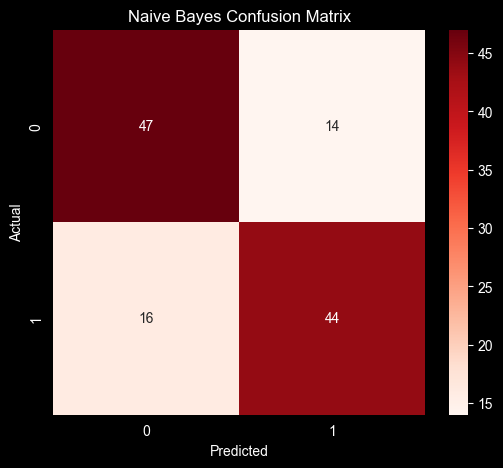

In [111]:
cm = confusion_matrix(y_test, nb_pred)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='Reds'
)

plt.title("Naive Bayes Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

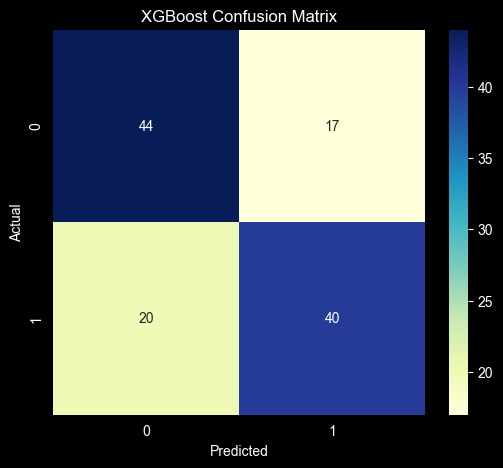

In [112]:
cm = confusion_matrix(y_test, xgb_pred)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='YlGnBu'
)

plt.title("XGBoost Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

Epoch 1/20
13/13 [==============================] - 4s 25ms/step - loss: 0.6657 - accuracy: 0.5984 - val_loss: 0.6065 - val_accuracy: 0.6907
Epoch 2/20
13/13 [==============================] - 0s 7ms/step - loss: 0.5975 - accuracy: 0.7098 - val_loss: 0.5582 - val_accuracy: 0.7423
Epoch 3/20
13/13 [==============================] - 0s 7ms/step - loss: 0.5500 - accuracy: 0.7409 - val_loss: 0.5384 - val_accuracy: 0.7320
Epoch 4/20
13/13 [==============================] - 0s 7ms/step - loss: 0.5331 - accuracy: 0.7358 - val_loss: 0.5188 - val_accuracy: 0.7526
Epoch 5/20
13/13 [==============================] - 0s 7ms/step - loss: 0.5110 - accuracy: 0.7513 - val_loss: 0.5073 - val_accuracy: 0.7732
Epoch 6/20
13/13 [==============================] - 0s 7ms/step - loss: 0.5006 - accuracy: 0.7565 - val_loss: 0.5022 - val_accuracy: 0.7732
Epoch 7/20
13/13 [==============================] - 0s 6ms/step - loss: 0.4868 - accuracy: 0.7746 - val_loss: 0.5122 - val_accuracy: 0.7423
Epoch 8/20
13/13 [=

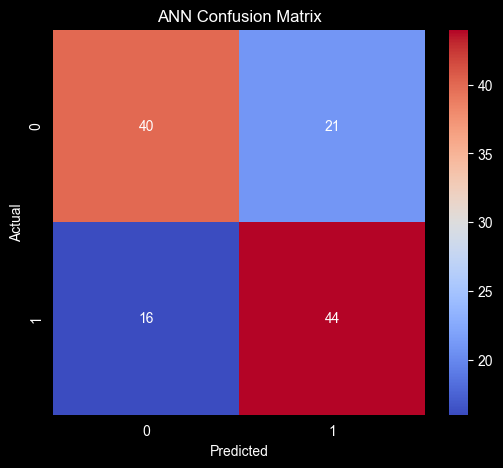

In [114]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create ANN model
ann_model = Sequential()

ann_model.add(Dense(128, activation='relu', input_shape=(X_train.shape[1],)))
ann_model.add(Dense(64, activation='relu'))
ann_model.add(Dense(1, activation='sigmoid'))

# Compile model
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train model
ann_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

# Predict probabilities
ann_pred_prob = ann_model.predict(X_test)

# Convert probabilities to 0/1
ann_pred = (ann_pred_prob > 0.5).astype(int)

# Flatten array
ann_pred = ann_pred.flatten()

# Confusion matrix
cm = confusion_matrix(y_test, ann_pred)

# Plot
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='coolwarm'
)

plt.title("ANN Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

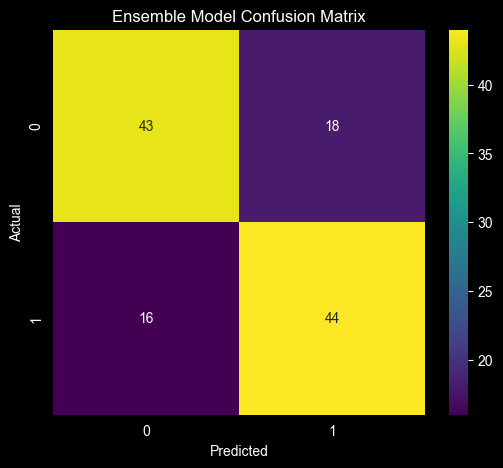

In [115]:
cm = confusion_matrix(y_test, ensemble_pred)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='viridis'
)

plt.title("Ensemble Model Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

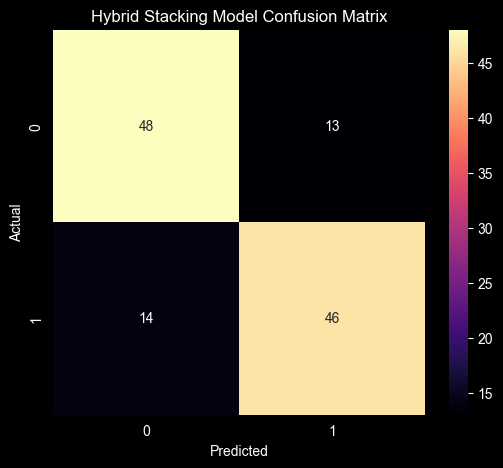

In [116]:
cm = confusion_matrix(y_test, stack_pred)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='magma'
)

plt.title("Hybrid Stacking Model Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

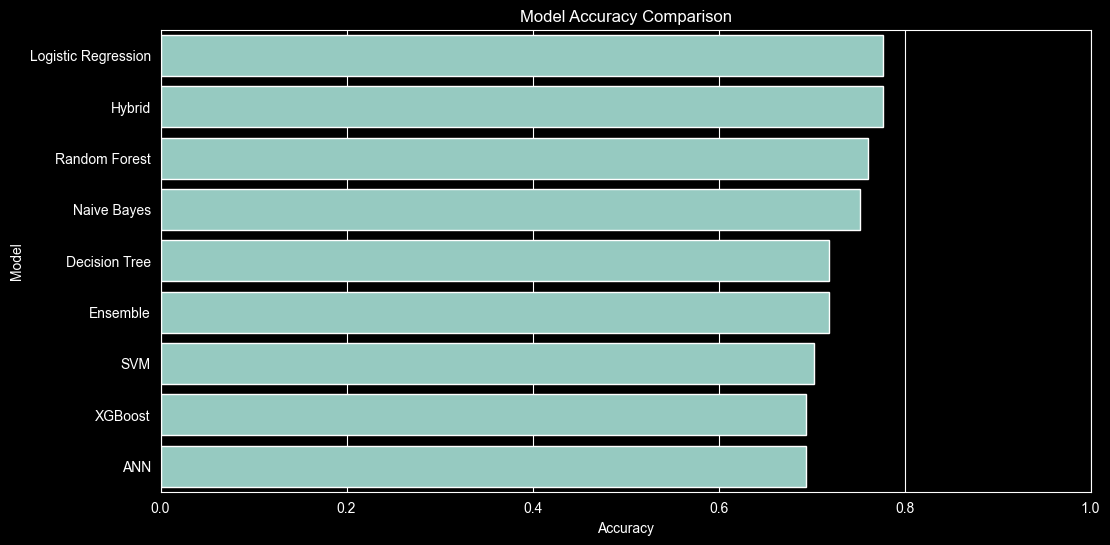

                 Model  Accuracy
0  Logistic Regression  0.776860
8               Hybrid  0.776860
2        Random Forest  0.760331
4          Naive Bayes  0.752066
1        Decision Tree  0.719008
7             Ensemble  0.719008
3                  SVM  0.702479
5              XGBoost  0.694215
6                  ANN  0.694215


In [117]:
model_results = {

    'Logistic Regression':
        accuracy_score(y_test, lr_pred),

    'Decision Tree':
        accuracy_score(y_test, dt_pred),

    'Random Forest':
        accuracy_score(y_test, rf_pred),

    'SVM':
        accuracy_score(y_test, svm_pred),

    'Naive Bayes':
        accuracy_score(y_test, nb_pred),

    'XGBoost':
        accuracy_score(y_test, xgb_pred),

    'ANN':
        accuracy_score(y_test, ann_pred),

    'Ensemble':
        accuracy_score(y_test, ensemble_pred),

    'Hybrid':
        accuracy_score(y_test, stack_pred)
}

results_df = pd.DataFrame({

    'Model': model_results.keys(),

    'Accuracy': model_results.values()
})

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
)

plt.figure(figsize=(12,6))

sns.barplot(

    x='Accuracy',

    y='Model',

    data=results_df
)

plt.title("Model Accuracy Comparison")

plt.xlim(0,1)

plt.show()

print(results_df)

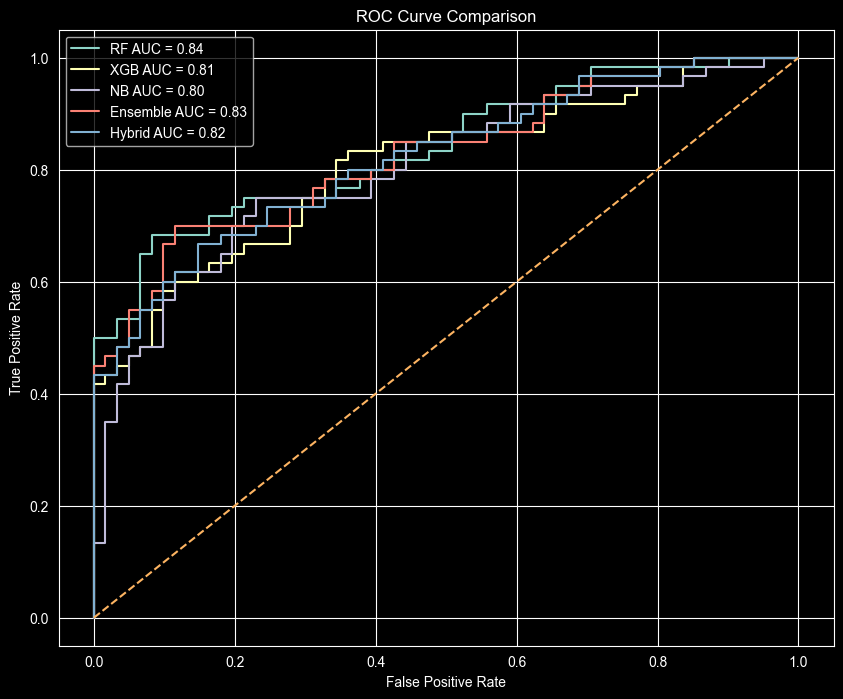

In [118]:
plt.figure(figsize=(10,8))

# Random Forest
rf_probs = rf.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, rf_probs)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr,
         label=f'RF AUC = {roc_auc:.2f}')

# XGBoost
xgb_probs = xgb.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, xgb_probs)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr,
         label=f'XGB AUC = {roc_auc:.2f}')

# Naive Bayes
nb_probs = nb.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, nb_probs)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr,
         label=f'NB AUC = {roc_auc:.2f}')

# Ensemble
ensemble_probs = ensemble_model.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, ensemble_probs)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr,
         label=f'Ensemble AUC = {roc_auc:.2f}')

# Hybrid
fpr, tpr, _ = roc_curve(y_test, hybrid_probs)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr,
         label=f'Hybrid AUC = {roc_auc:.2f}')

# Random Line
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

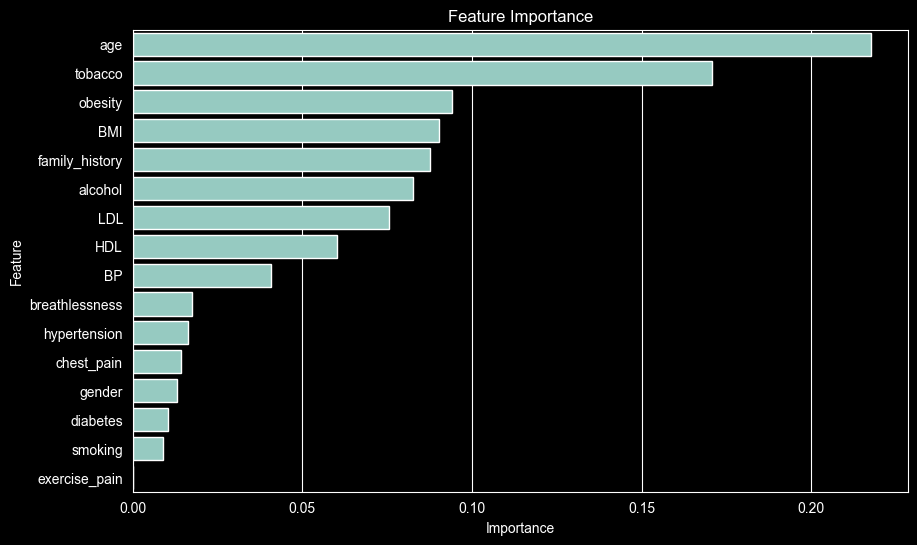

           Feature  Importance
0              age    0.217528
9          tobacco    0.170664
7          obesity    0.094020
2              BMI    0.090392
6   family_history    0.087508
8          alcohol    0.082689
10             LDL    0.075560
11             HDL    0.060279
12              BP    0.040817
14  breathlessness    0.017589
4     hypertension    0.016392
13      chest_pain    0.014167
1           gender    0.013003
5         diabetes    0.010416
3          smoking    0.008974
15   exercise_pain    0.000000


In [119]:
importance_df = pd.DataFrame({

    'Feature': X.columns,

    'Importance': rf.feature_importances_

})

importance_df = importance_df.sort_values(

    by='Importance',

    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(

    x='Importance',

    y='Feature',

    data=importance_df
)

plt.title("Feature Importance")

plt.show()

print(importance_df)

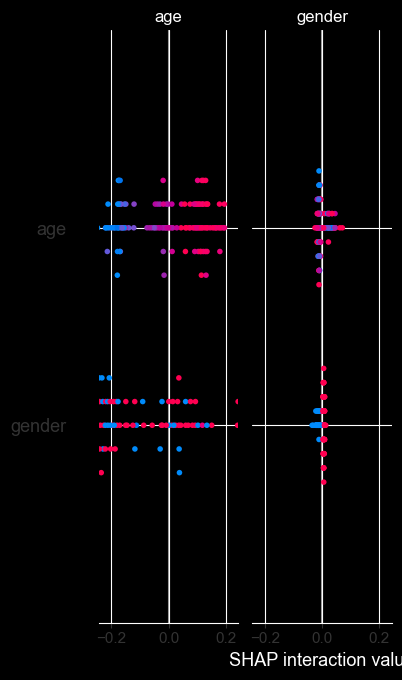

In [120]:
import shap

explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(

    shap_values,

    X_test,

    feature_names=X.columns
)

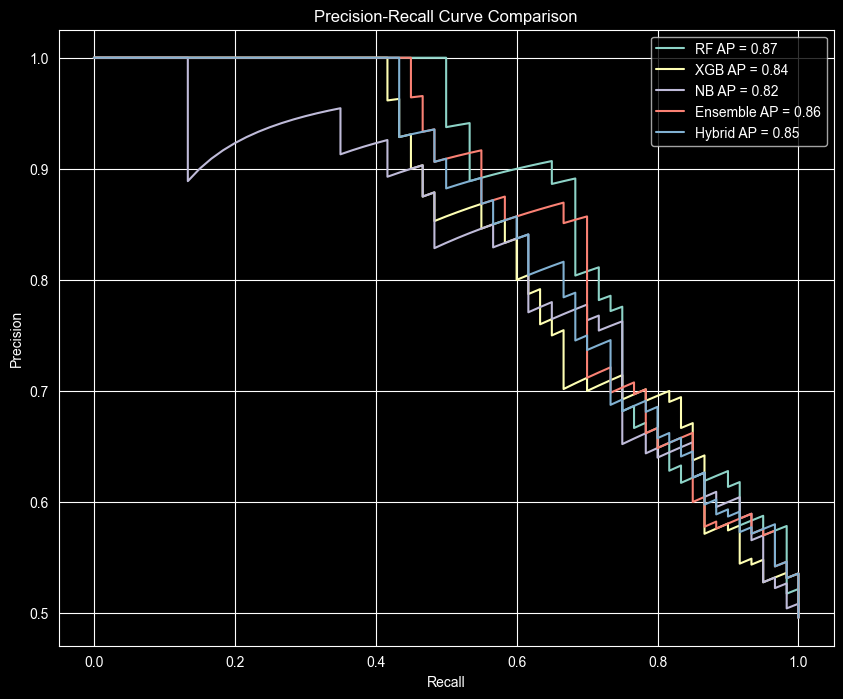

In [121]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

plt.figure(figsize=(10,8))

# Random Forest
rf_probs = rf.predict_proba(X_test)[:,1]

precision, recall, _ = precision_recall_curve(
    y_test,
    rf_probs
)

ap = average_precision_score(y_test, rf_probs)

plt.plot(
    recall,
    precision,
    label=f'RF AP = {ap:.2f}'
)

# XGBoost
xgb_probs = xgb.predict_proba(X_test)[:,1]

precision, recall, _ = precision_recall_curve(
    y_test,
    xgb_probs
)

ap = average_precision_score(y_test, xgb_probs)

plt.plot(
    recall,
    precision,
    label=f'XGB AP = {ap:.2f}'
)

# Naive Bayes
nb_probs = nb.predict_proba(X_test)[:,1]

precision, recall, _ = precision_recall_curve(
    y_test,
    nb_probs
)

ap = average_precision_score(y_test, nb_probs)

plt.plot(
    recall,
    precision,
    label=f'NB AP = {ap:.2f}'
)

# Ensemble
ensemble_probs = ensemble_model.predict_proba(X_test)[:,1]

precision, recall, _ = precision_recall_curve(
    y_test,
    ensemble_probs
)

ap = average_precision_score(y_test, ensemble_probs)

plt.plot(
    recall,
    precision,
    label=f'Ensemble AP = {ap:.2f}'
)

# Hybrid
precision, recall, _ = precision_recall_curve(
    y_test,
    hybrid_probs
)

ap = average_precision_score(y_test, hybrid_probs)

plt.plot(
    recall,
    precision,
    label=f'Hybrid AP = {ap:.2f}'
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve Comparison")

plt.legend()

plt.show()

In [122]:
from sklearn.metrics import classification_report

def plot_classification_report(y_true, y_pred, title):

    report = classification_report(
        y_true,
        y_pred,
        output_dict=True
    )

    report_df = pd.DataFrame(report).transpose()

    plt.figure(figsize=(8,5))

    sns.heatmap(

        report_df.iloc[:-1, :-1],

        annot=True,

        cmap='Blues'
    )

    plt.title(title)

    plt.show()

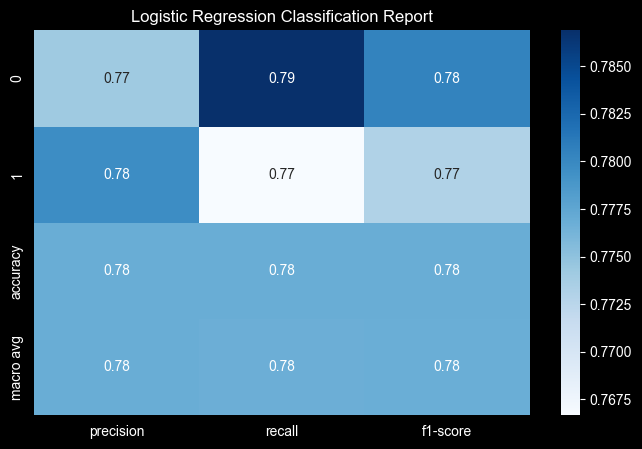

In [123]:
plot_classification_report(

    y_test,

    lr_pred,

    "Logistic Regression Classification Report"
)

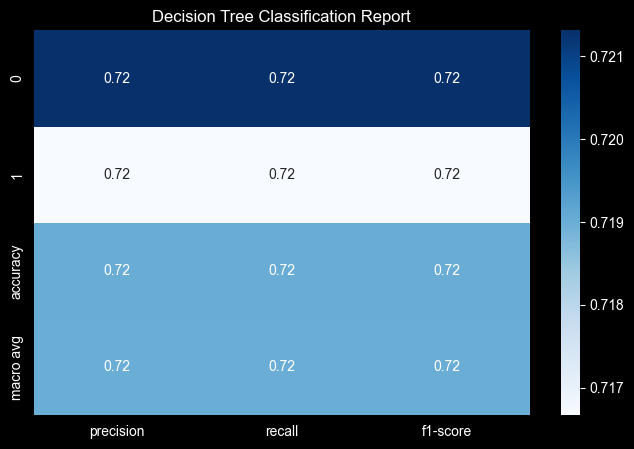

In [124]:
plot_classification_report(

    y_test,

    dt_pred,

    "Decision Tree Classification Report"
)

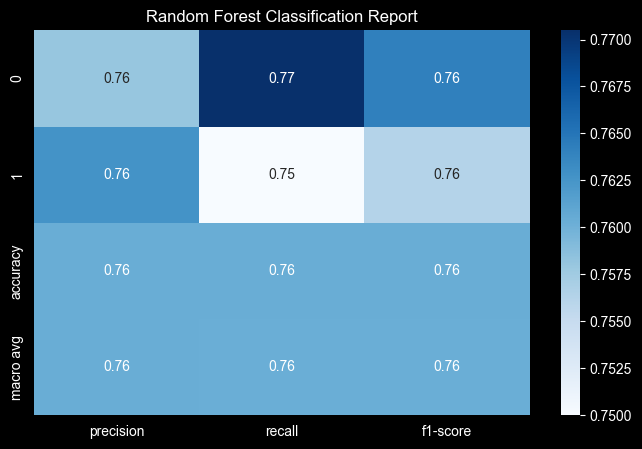

In [125]:
plot_classification_report(

    y_test,

    rf_pred,

    "Random Forest Classification Report"
)

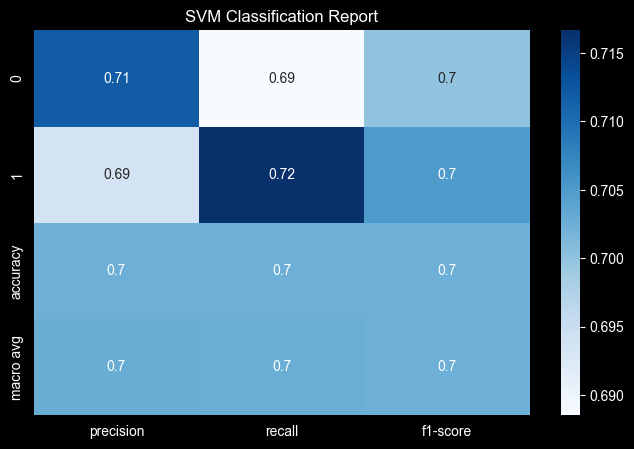

In [126]:
plot_classification_report(

    y_test,

    svm_pred,

    "SVM Classification Report"
)

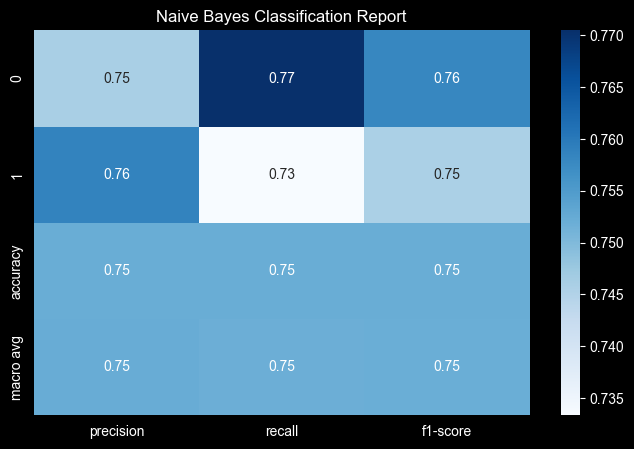

In [127]:
plot_classification_report(

    y_test,

    nb_pred,

    "Naive Bayes Classification Report"
)

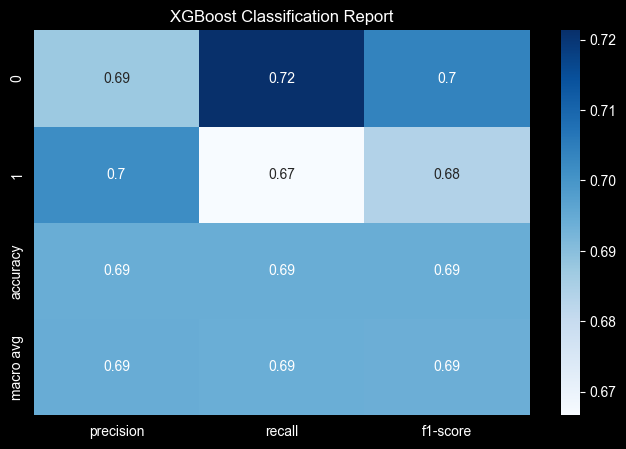

In [128]:
plot_classification_report(

    y_test,

    xgb_pred,

    "XGBoost Classification Report"
)

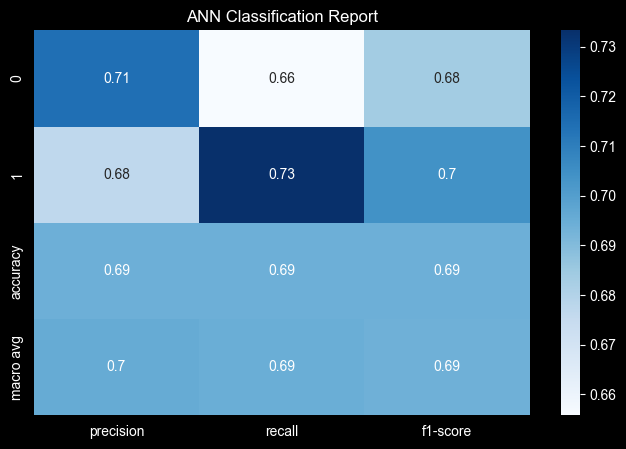

In [129]:
plot_classification_report(

    y_test,

    ann_pred,

    "ANN Classification Report"
)

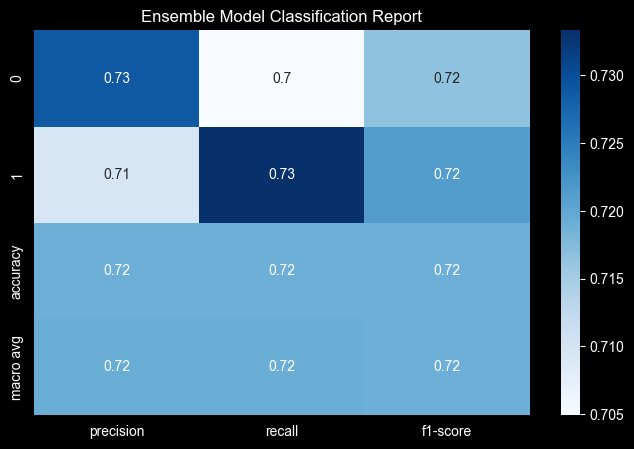

In [130]:
plot_classification_report(

    y_test,

    ensemble_pred,

    "Ensemble Model Classification Report"
)

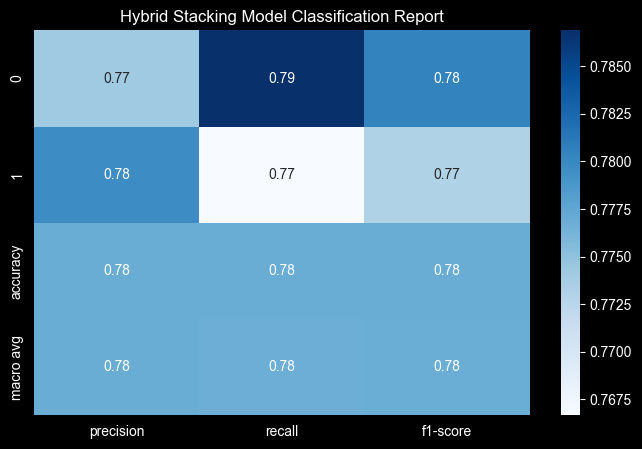

In [131]:
plot_classification_report(

    y_test,

    stack_pred,

    "Hybrid Stacking Model Classification Report"
)

In [132]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

metrics_df = pd.DataFrame({

    'Model': [

        'LR',

        'DT',

        'RF',

        'SVM',

        'NB',

        'XGB',

        'ANN',

        'Ensemble',

        'Hybrid'
    ],

    'Precision': [

        precision_score(y_test, lr_pred),

        precision_score(y_test, dt_pred),

        precision_score(y_test, rf_pred),

        precision_score(y_test, svm_pred),

        precision_score(y_test, nb_pred),

        precision_score(y_test, xgb_pred),

        precision_score(y_test, ann_pred),

        precision_score(y_test, ensemble_pred),

        precision_score(y_test, stack_pred)
    ],

    'Recall': [

        recall_score(y_test, lr_pred),

        recall_score(y_test, dt_pred),

        recall_score(y_test, rf_pred),

        recall_score(y_test, svm_pred),

        recall_score(y_test, nb_pred),

        recall_score(y_test, xgb_pred),

        recall_score(y_test, ann_pred),

        recall_score(y_test, ensemble_pred),

        recall_score(y_test, stack_pred)
    ],

    'F1 Score': [

        f1_score(y_test, lr_pred),

        f1_score(y_test, dt_pred),

        f1_score(y_test, rf_pred),

        f1_score(y_test, svm_pred),

        f1_score(y_test, nb_pred),

        f1_score(y_test, xgb_pred),

        f1_score(y_test, ann_pred),

        f1_score(y_test, ensemble_pred),

        f1_score(y_test, stack_pred)
    ]
})

print(metrics_df)

      Model  Precision    Recall  F1 Score
0        LR   0.779661  0.766667  0.773109
1        DT   0.716667  0.716667  0.716667
2        RF   0.762712  0.750000  0.756303
3       SVM   0.693548  0.716667  0.704918
4        NB   0.758621  0.733333  0.745763
5       XGB   0.701754  0.666667  0.683761
6       ANN   0.676923  0.733333  0.704000
7  Ensemble   0.709677  0.733333  0.721311
8    Hybrid   0.779661  0.766667  0.773109


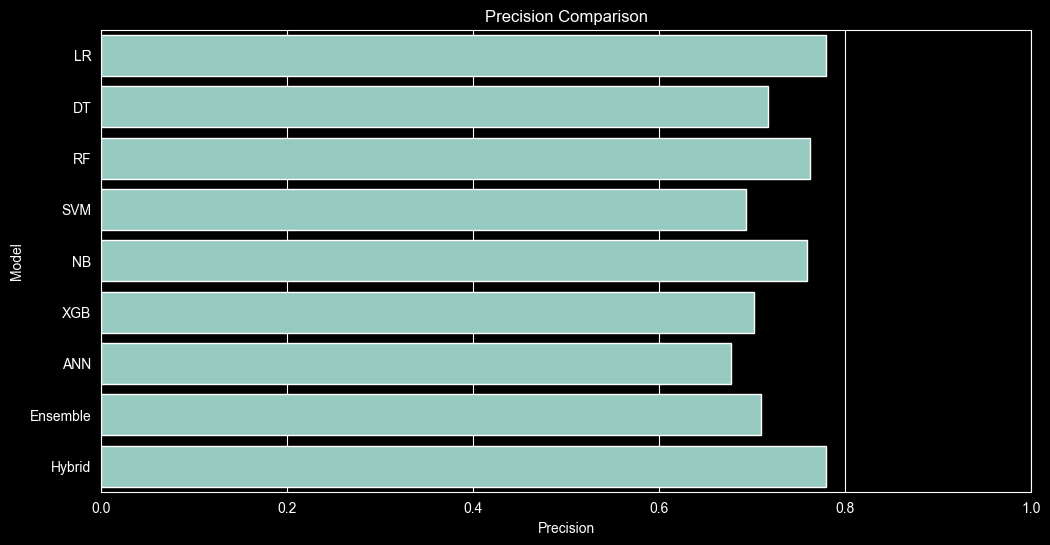

In [133]:
plt.figure(figsize=(12,6))

sns.barplot(

    x='Precision',

    y='Model',

    data=metrics_df
)

plt.title("Precision Comparison")

plt.xlim(0,1)

plt.show()

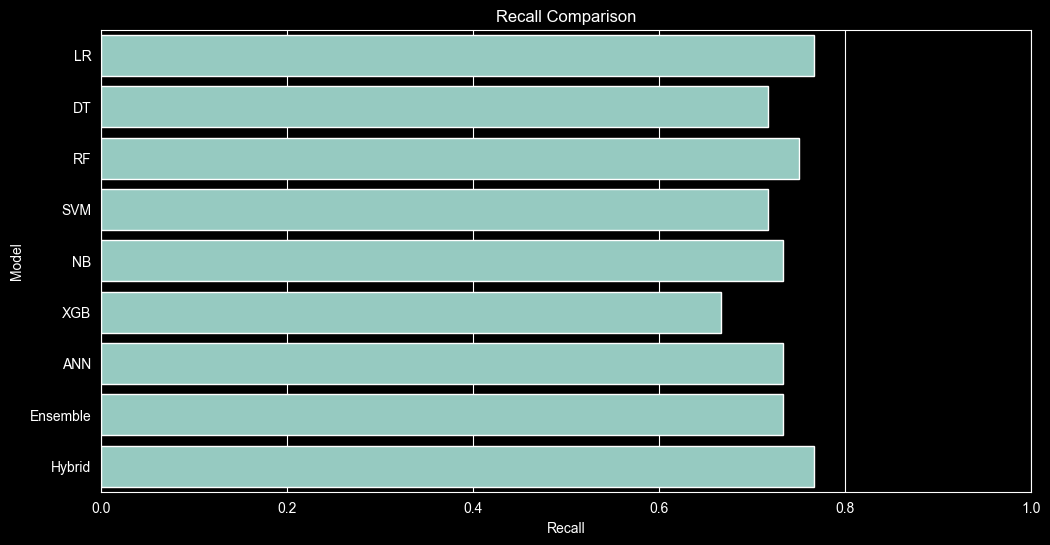

In [134]:
plt.figure(figsize=(12,6))

sns.barplot(

    x='Recall',

    y='Model',

    data=metrics_df
)

plt.title("Recall Comparison")

plt.xlim(0,1)

plt.show()

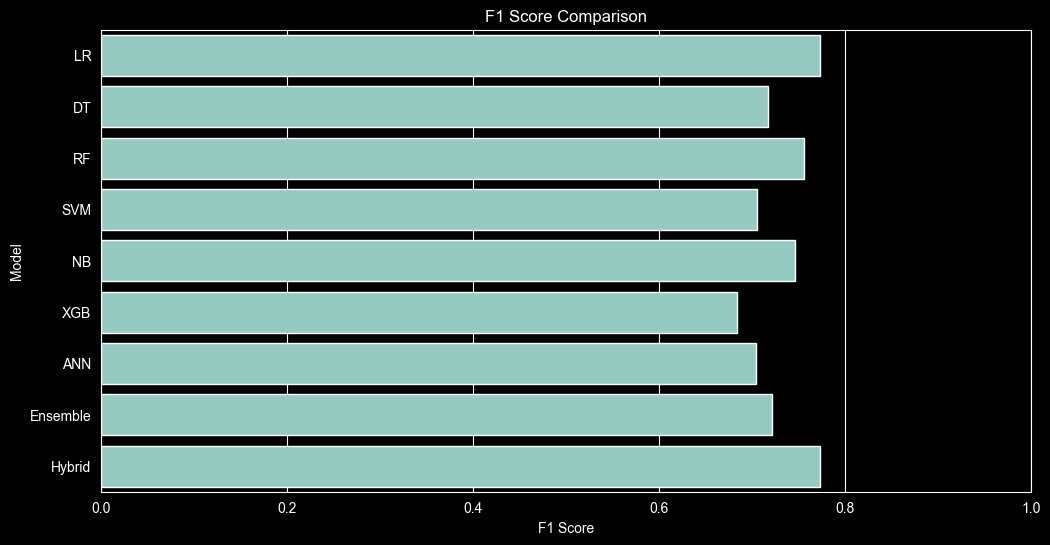

In [135]:
plt.figure(figsize=(12,6))

sns.barplot(

    x='F1 Score',

    y='Model',

    data=metrics_df
)

plt.title("F1 Score Comparison")

plt.xlim(0,1)

plt.show()

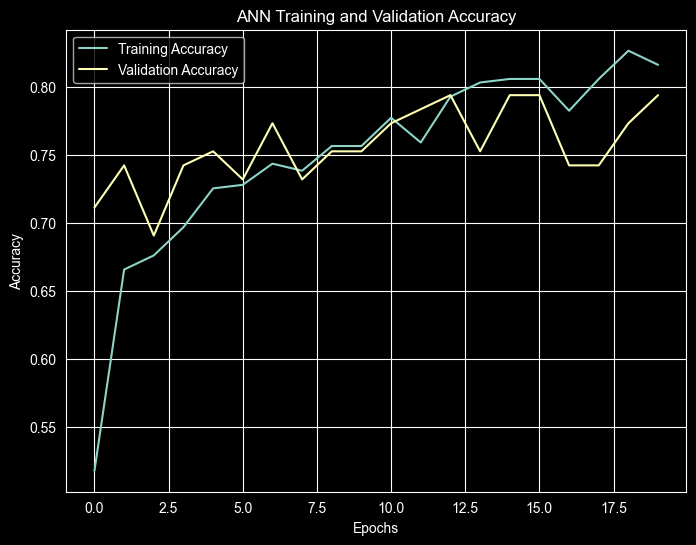

In [136]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(

    history.history['accuracy'],

    label='Training Accuracy'
)

plt.plot(

    history.history['val_accuracy'],

    label='Validation Accuracy'
)

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.title("ANN Training and Validation Accuracy")

plt.legend()

plt.show()

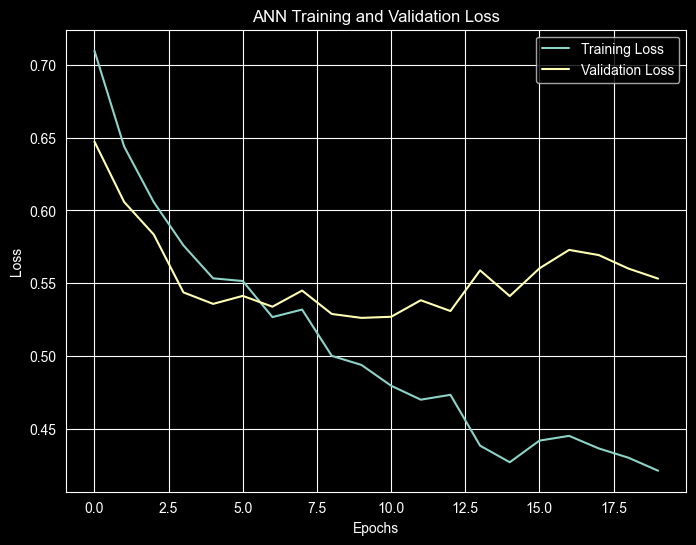

In [137]:
plt.figure(figsize=(8,6))

plt.plot(

    history.history['loss'],

    label='Training Loss'
)

plt.plot(

    history.history['val_loss'],

    label='Validation Loss'
)

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.title("ANN Training and Validation Loss")

plt.legend()

plt.show()

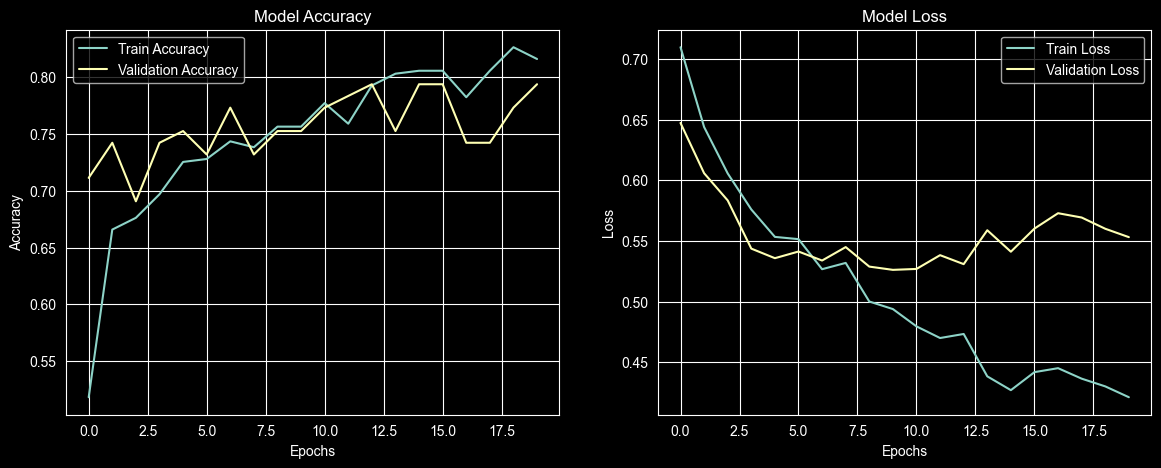

In [138]:
fig, axes = plt.subplots(

    1,

    2,

    figsize=(14,5)
)

# Accuracy
axes[0].plot(
    history.history['accuracy'],
    label='Train Accuracy'
)

axes[0].plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

axes[0].set_title("Model Accuracy")

axes[0].set_xlabel("Epochs")

axes[0].set_ylabel("Accuracy")

axes[0].legend()

# Loss
axes[1].plot(
    history.history['loss'],
    label='Train Loss'
)

axes[1].plot(
    history.history['val_loss'],
    label='Validation Loss'
)

axes[1].set_title("Model Loss")

axes[1].set_xlabel("Epochs")

axes[1].set_ylabel("Loss")

axes[1].legend()

plt.show()

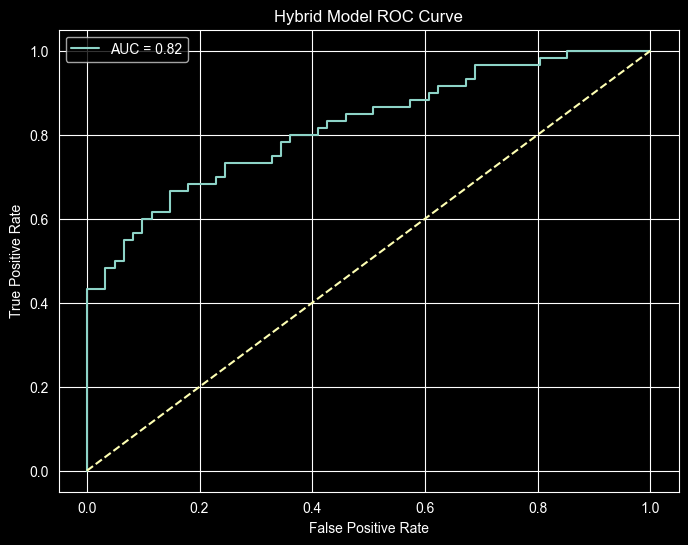

In [139]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

fpr, tpr, thresholds = roc_curve(
    y_test,
    hybrid_probs
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))

plt.plot(

    fpr,

    tpr,

    label=f'AUC = {roc_auc:.2f}'
)

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Hybrid Model ROC Curve")

plt.legend()

plt.show()

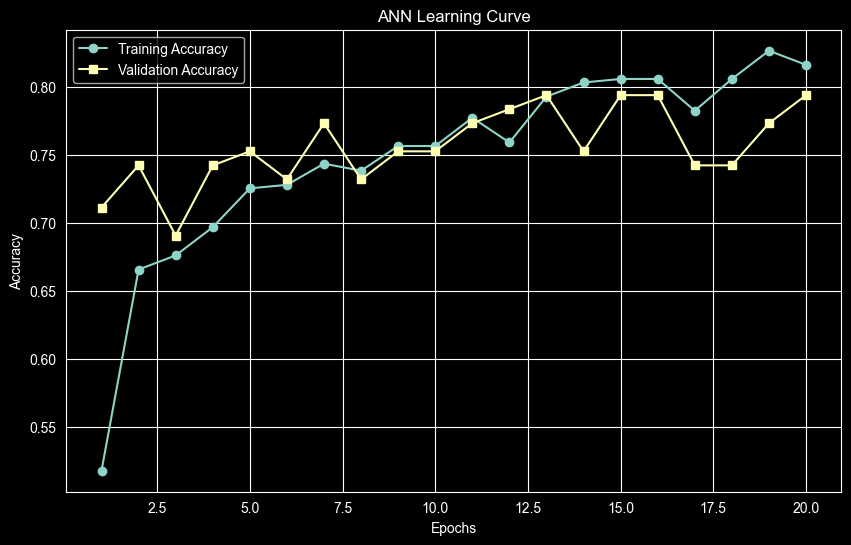

In [140]:
epochs_range = range(
    1,
    len(history.history['accuracy']) + 1
)

plt.figure(figsize=(10,6))

plt.plot(

    epochs_range,

    history.history['accuracy'],

    marker='o',

    label='Training Accuracy'
)

plt.plot(

    epochs_range,

    history.history['val_accuracy'],

    marker='s',

    label='Validation Accuracy'
)

plt.title("ANN Learning Curve")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

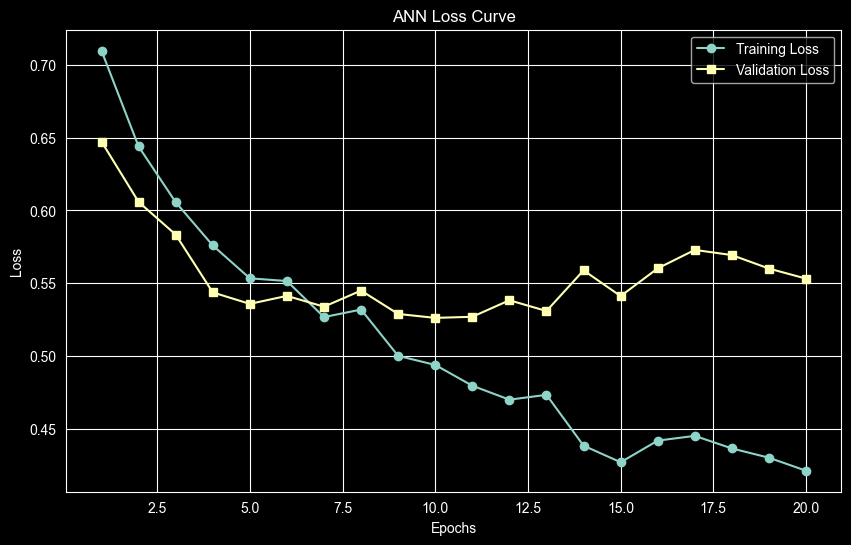

In [141]:
plt.figure(figsize=(10,6))

plt.plot(

    epochs_range,

    history.history['loss'],

    marker='o',

    label='Training Loss'
)

plt.plot(

    epochs_range,

    history.history['val_loss'],

    marker='s',

    label='Validation Loss'
)

plt.title("ANN Loss Curve")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [142]:
import pickle

with open("random_forest_model.pkl", "wb") as f:

    pickle.dump(rf, f)

print("Random Forest model saved.")

Random Forest model saved.


In [143]:
with open("xgboost_model.pkl", "wb") as f:

    pickle.dump(xgb, f)

print("XGBoost model saved.")

XGBoost model saved.


In [144]:
with open("naive_bayes_model.pkl", "wb") as f:

    pickle.dump(nb, f)

print("Naive Bayes model saved.")

Naive Bayes model saved.


In [145]:
with open("naive_bayes_model.pkl", "wb") as f:

    pickle.dump(nb, f)

print("Naive Bayes model saved.")

Naive Bayes model saved.


In [146]:
with open("ensemble_model.pkl", "wb") as f:

    pickle.dump(ensemble_model, f)

print("Ensemble model saved.")

Ensemble model saved.


In [147]:
with open("hybrid_meta_model.pkl", "wb") as f:

    pickle.dump(meta_model, f)

print("Hybrid meta model saved.")

Hybrid meta model saved.


In [148]:
with open("scaler.pkl", "wb") as f:

    pickle.dump(scaler, f)

print("Scaler saved.")

Scaler saved.


In [149]:
with open("label_encoders.pkl", "wb") as f:

    pickle.dump(encoders, f)

print("Encoders saved.")

Encoders saved.


In [150]:
feature_names = X.columns.tolist()

with open("feature_names.pkl", "wb") as f:

    pickle.dump(feature_names, f)

print("Feature names saved.")

Feature names saved.


In [151]:
ann.save("ann_model.h5")

print("ANN model saved.")

ANN model saved.
